# Single Gene Analysis

In [1]:
# imports
import os
import polars as pl
import pandas as pd
import numpy as np
from tqdm import tqdm
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import umap
from functools import reduce
import operator
from adjustText import adjust_text

import sys
sys.path.append("../../../../1_allele_collection/2_analysis")
from plot_utils import *
sys.path.append("../1_snakemake_pipeline/2025_varchamp_snakemake")
from img_utils import *
sys.path.append("../../..")
from analyses_plot_utils import *

sns.set_style(style='white')
sns.set_context("notebook", font_scale=.9)

## 1. Loading data

In [2]:
imaging_summary_clinvar = pl.read_csv("../../3_outputs/imaging_analyses_summary_clinvar.tsv", separator="\t", infer_schema_length=10000000)

In [3]:
allele_meta_df = pl.DataFrame()
allele_meta_df_dict, img_well_qc_sum_dict = {}, {}

for bio_rep, bio_rep_batches in BIO_REP_BATCHES_DICT.items():
    for batch_id in bio_rep_batches:
        allele_meta_df_batch = pl.DataFrame()
        platemaps = [file for file in os.listdir(PLATEMAP_DIR.format(batch_id=batch_id)) if file.endswith(".txt")]
        for platemap in platemaps:
            platemap_df = pl.read_csv(os.path.join(PLATEMAP_DIR.format(batch_id=batch_id), platemap), separator="\t", infer_schema_length=100000)
            allele_meta_df_batch = pl.concat([allele_meta_df_batch, 
                                        platemap_df.filter((pl.col("node_type").is_not_null()))], # (~pl.col("node_type").is_in(["TC","NC","PC"]))&
                                        how="diagonal_relaxed").sort("plate_map_name")
            allele_meta_df_batch = allele_meta_df_batch.with_columns(pl.col("plate_map_name").alias("plate_map")) ## str.split('_').list.get(0).
            # display(allele_meta_df.head())
        allele_meta_df = pl.concat([
            allele_meta_df,
            allele_meta_df_batch
        ], how="diagonal_relaxed")#.sort("plate_map_name") ## (~pl.col("node_type").is_in(["TC","NC","PC"]))&
    allele_meta_df_dict[bio_rep] = allele_meta_df_batch

    img_well_qc_sum = pl.read_csv(f"{IMGS_QC_METRICS_DIR}/{bio_rep}/plate-well-level_img_qc_sum.csv")
    img_well_qc_sum = img_well_qc_sum.with_columns(
        pl.col("channel").replace("DAPI", "DNA").alias("channel")
    )
    img_well_qc_sum_morph = img_well_qc_sum.filter(pl.col("channel")!="GFP")
    img_well_qc_sum_morph = img_well_qc_sum_morph.group_by(["plate","well"]).agg(
        pl.col("is_bg").max().alias("is_bg"),
        pl.col("s2n_ratio").mean().alias("s2n_ratio")
    ).with_columns(pl.lit("Morph").alias("channel"))
    img_well_qc_sum = pl.concat([
        img_well_qc_sum.select(pl.col(["plate","well","channel","is_bg","s2n_ratio"])),
        img_well_qc_sum_morph.select(pl.col(["plate","well","channel","is_bg","s2n_ratio"])),
    ], how="vertical_relaxed")
    img_well_qc_sum_dict[bio_rep] = img_well_qc_sum

## 2. Loading CellProfiler Features

In [14]:
gene = "KCNJ2"
FEAT = "GFP"

## QC-ed PQ files
ALL_PROF_QC = PROF_DIR + "/{batch_id}/profiles_tcdropped_filtered_var_mad_outlier.parquet"
PASS_QC_PROF_PQ = PROF_DIR + "/{batch_id}/profiles_tcdropped_filtered_var_mad_outlier_featselect_filtcells.parquet"

feat_df = pl.read_csv("../../3_outputs/feat_importance_gt1e-3_all_alleles.csv")

In [48]:
gene_variant_scores = imaging_summary_clinvar.filter((pl.col("gene_allele").str.contains(gene))) ## &(pl.col(f"Altered_95th_perc_{feat}")==1)
variant_list = list(gene_variant_scores["gene_allele"]) + [gene]
bio_reps = list(gene_variant_scores["Metadata_Bio_Batch"].unique())
# gene_variant_scores["Metadata_Bio_Batch"].unique()
gene_variant_scores

feat_df_var = feat_df.select(pl.col(["cp_feature"]+list(gene_variant_scores["gene_allele"])))
feat_df_var = feat_df_var.filter(
    pl.mean_horizontal(list(gene_variant_scores["gene_allele"])) >= 0.01
)
sig_diff_feat = list(feat_df_var["cp_feature"])

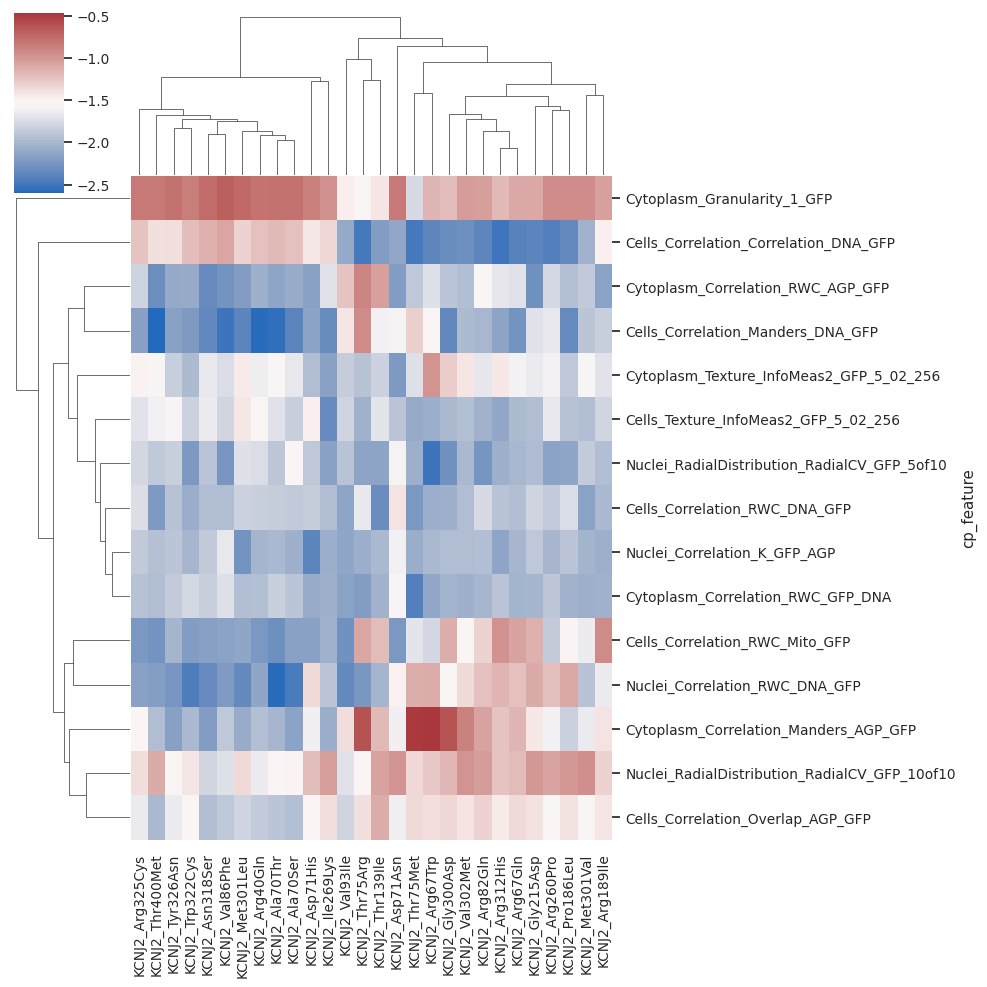

In [32]:
sns.clustermap(
    data=feat_df_var.to_pandas().set_index("cp_feature").apply(np.log10),
    cmap='vlag',
)

In [10]:
# Paths
ref_var_cell_qc_prof_df = pl.DataFrame()
target_gene_alleles = []
meta_cols = [
    "Metadata_CellID",
    "Metadata_gene_allele",
    "Metadata_Well",
    "Metadata_Plate",
    "Metadata_node_type"
]

# Get meta features
for bio_rep in bio_reps:
    bio_rep_batches = BIO_REP_BATCHES_DICT[bio_rep]
    ## ONLY grep the allele come from the bio-rep
    allele_batch_df = imaging_summary_clinvar.filter(pl.col("Metadata_Bio_Batch")==bio_rep)
    batch_allele_list = [al for al in list(allele_batch_df["gene_allele"]) + list(allele_batch_df["Gene"].unique()) if al in variant_list]
    for batch_id in bio_rep_batches:
        batch_alleles = (
            pl.scan_parquet(
                PASS_QC_PROF_PQ.format(batch_id=batch_id)
            )
            .filter(pl.col("Metadata_gene_allele").is_in(batch_allele_list))
            .with_columns(
                pl.concat_str(
                    [
                        "Metadata_Plate",
                        "Metadata_Well",
                        "Metadata_ImageNumber",
                        "Metadata_ObjectNumber",
                    ],
                    separator="_",
                ).alias("Metadata_CellID")
            )
        ).collect()
        # feat_cols = [col for col in batch_alleles.columns if ("AGP".lower() in col.lower() or "DNA".lower() in col.lower() or "Mito".lower() in col.lower()) and ("GFP".lower() not in col.lower())]
        batch_alleles = batch_alleles.join(
            img_well_qc_sum_dict[bio_rep].filter(pl.col("channel")==FEAT).select(pl.col("plate", "well", "is_bg")),
            left_on=["Metadata_Plate", "Metadata_Well"],
            right_on=["plate", "well"]
        ).filter(
            ~pl.col("is_bg")
        ).select(pl.col(meta_cols))
        ref_var_cell_qc_prof_df = pl.concat([ref_var_cell_qc_prof_df, batch_alleles], how="diagonal_relaxed")

In [42]:
# Paths
ref_var_cell_all_prof_list = []
for bio_rep, bio_rep_batches in BIO_REP_BATCHES_DICT.items():
    ## ONLY grep the allele come from the bio-rep
    allele_batch_df = imaging_summary_clinvar.filter(pl.col("Metadata_Bio_Batch")==bio_rep)
    batch_allele_list = [al for al in list(allele_batch_df["gene_allele"]) + list(allele_batch_df["Gene"].unique()) if al in variant_list]
    for batch_id in bio_rep_batches:
        batch_alleles = (
            pl.scan_parquet(
                ALL_PROF_QC.format(batch_id=batch_id)
            )
            .filter(pl.col("Metadata_gene_allele").is_in(batch_allele_list))
            .with_columns(
                pl.concat_str(
                    [
                        "Metadata_Plate",
                        "Metadata_Well",
                        "Metadata_ImageNumber",
                        "Metadata_ObjectNumber",
                    ],
                    separator="_",
                ).alias("Metadata_CellID")
            )
        )
        ref_var_cell_all_prof_list.append(batch_alleles)

# all_feat_cols = reduce(set.intersection, map(set, 
#                                              [[col for col in ref_var_cell_all_prof.collect_schema() \
#                                                if (FEAT.lower() in col.lower()) and ("Brightfield".lower() not in col.lower())] for ref_var_cell_all_prof in ref_var_cell_all_prof_list]))
# select_cols = list(all_feat_cols) + ["Metadata_CellID"]
select_cols = ["Metadata_CellID"] + sig_diff_feat
ref_var_cell_all_prof_df = pl.concat(
    [batch_alleles.select([c for c in select_cols if c in batch_alleles.collect_schema()]).collect() for batch_alleles in ref_var_cell_all_prof_list],
    how="diagonal"
)
# This method of joining ensures that only cells past filters are included in the abundance analysis
ref_var_cell_all_prof_df = ref_var_cell_qc_prof_df.join(ref_var_cell_all_prof_df, 
                                                        on="Metadata_CellID", 
                                                        how="left", coalesce=True)

In [45]:
# ref_var_cell_all_prof_df.filter(pl.col("Cells_Correlation_Overlap_AGP_GFP").is_null())

In [49]:
ref_var_cell_all_prof_df.filter(pl.col("Metadata_gene_allele")=="KCNJ2").select(sig_diff_feat).mean()

Cells_Correlation_RWC_Mito_GFP,Nuclei_Correlation_K_GFP_AGP,Cytoplasm_Correlation_RWC_GFP_DNA,Cytoplasm_Granularity_1_GFP,Cells_Correlation_RWC_DNA_GFP,Cells_Correlation_Correlation_DNA_GFP,Nuclei_RadialDistribution_RadialCV_GFP_5of10,Nuclei_Correlation_RWC_DNA_GFP,Nuclei_RadialDistribution_RadialCV_GFP_10of10,Cytoplasm_Correlation_RWC_AGP_GFP,Cells_Correlation_Overlap_AGP_GFP,Cytoplasm_Texture_InfoMeas2_GFP_5_02_256,Cells_Texture_InfoMeas2_GFP_5_02_256,Cells_Correlation_Manders_DNA_GFP,Cytoplasm_Correlation_Manders_AGP_GFP
f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32
-0.022437,0.679429,0.170651,-0.595647,0.155372,-0.825076,0.903575,-0.43913,0.8666,-0.078751,-0.603686,0.201735,0.03261,-1.596181,-2.193562


In [50]:
ref_var_cell_all_prof_df.filter(pl.col("Metadata_gene_allele")=="KCNJ2").select(sig_diff_feat).std()

Cells_Correlation_RWC_Mito_GFP,Nuclei_Correlation_K_GFP_AGP,Cytoplasm_Correlation_RWC_GFP_DNA,Cytoplasm_Granularity_1_GFP,Cells_Correlation_RWC_DNA_GFP,Cells_Correlation_Correlation_DNA_GFP,Nuclei_RadialDistribution_RadialCV_GFP_5of10,Nuclei_Correlation_RWC_DNA_GFP,Nuclei_RadialDistribution_RadialCV_GFP_10of10,Cytoplasm_Correlation_RWC_AGP_GFP,Cells_Correlation_Overlap_AGP_GFP,Cytoplasm_Texture_InfoMeas2_GFP_5_02_256,Cells_Texture_InfoMeas2_GFP_5_02_256,Cells_Correlation_Manders_DNA_GFP,Cytoplasm_Correlation_Manders_AGP_GFP
f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32
1.247788,1.697939,1.246433,0.854482,0.988603,1.246015,2.634196,1.607123,2.679328,1.33024,1.893737,0.937506,1.00755,3.924718,5.781113


In [57]:
ref_var_cell_all_prof_df.filter(pl.col("Metadata_gene_allele")=="KCNJ2").select(sig_diff_feat).mean().to_numpy()

array([[-0.02243662,  0.67942894,  0.17065081, -0.5956468 ,  0.1553715 ,
        -0.8250755 ,  0.9035749 , -0.4391304 ,  0.86659956, -0.07875057,
        -0.6036858 ,  0.20173454,  0.03260977, -1.5961813 , -2.1935623 ]],
      dtype=float32)

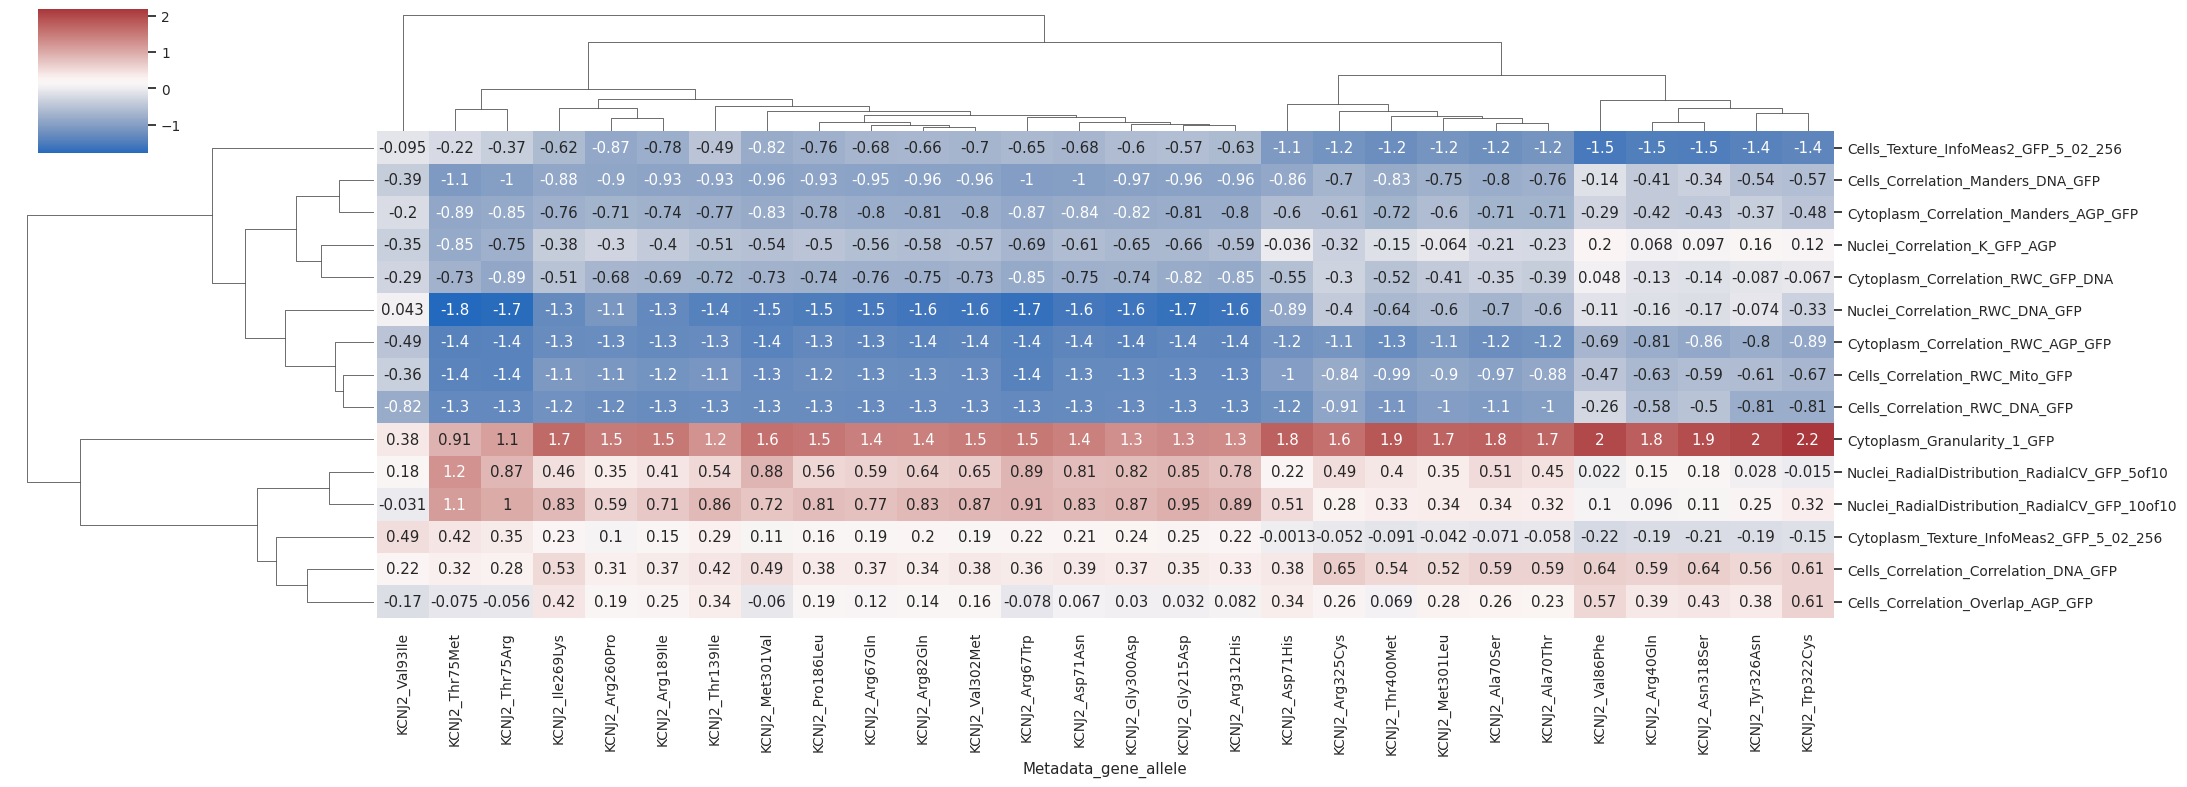

In [72]:
z_score_feat = ((ref_var_cell_all_prof_df.filter(pl.col("Metadata_gene_allele")!="KCNJ2").group_by(
    "Metadata_gene_allele"
).agg(
    pl.col(col).median().alias(col)
    for col in ref_var_cell_all_prof_df.columns
    if not col.startswith("Metadata_")
).to_pandas().set_index("Metadata_gene_allele") - \
ref_var_cell_all_prof_df.filter(pl.col("Metadata_gene_allele")=="KCNJ2").select(sig_diff_feat).mean().to_numpy()) / \
ref_var_cell_all_prof_df.filter(pl.col("Metadata_gene_allele")=="KCNJ2").select(sig_diff_feat).std().to_numpy()).T

sns.clustermap(
    data=z_score_feat,
    cmap="vlag",
    # square=True,
    annot=z_score_feat.values,
    figsize=(22,8)
)

In [567]:
# ref_var_cell_all_prof_df = ref_var_cell_all_prof_df.with_columns(
#     pl.col("Metadata_Plate")
#       # capture a “B” followed by any non-underscore chars up to the first “A”
#       .str.extract(r"(B[^_]*?A)", 1)
#       .alias("Metadata_Batch")
# ).with_columns(
#     pl.col("Metadata_Batch").replace(BIO_BATCH_MAP_DICT).alias("Metadata_Bio_Batch")
# )

# ref_var_allele_batch_all_prof_df = ref_var_cell_all_prof_df.group_by(
#     "Metadata_Plate", "Metadata_Well", "Metadata_gene_allele", "Metadata_Bio_Batch"
# ).agg(
#     pl.col(col).median().alias(col)
#     for col in all_feat_cols
#     if not col.startswith("Metadata_")
# ).group_by(
#     "Metadata_gene_allele", "Metadata_Bio_Batch"
# ).agg(
#     pl.col(col).median().alias(col)
#     for col in all_feat_cols
#     if not col.startswith("Metadata_")
# ).unique(subset=["Metadata_gene_allele","Metadata_Bio_Batch"])

# non_null_cols_batch = [c for c in feat_df["cp_feature"].to_list() if c in ref_var_allele_batch_all_prof_df.columns]
# var_allele_meta_cols = [col for col in ref_var_allele_batch_all_prof_df.columns if "Metadata" in col]
# ref_var_allele_batch_all_prof_df = ref_var_allele_batch_all_prof_df.select(
#     var_allele_meta_cols+non_null_cols_batch
# )
# ref_var_allele_batch_all_prof_df

In [568]:
ref_var_allele_batch_proc_prof_df = inverse_normal_transform(ref_var_allele_batch_all_prof_df)
ref_var_allele_batch_proc_prof_df = remove_corr_feats(ref_var_allele_batch_proc_prof_df)

non_null_cols_batch = [col for col in ref_var_allele_batch_proc_prof_df.columns if not ref_var_allele_batch_proc_prof_df[col].is_null().any() and "Metadata" not in col]
ref_var_allele_batch_proc_prof_df = ref_var_allele_batch_proc_prof_df.select(
    var_allele_meta_cols + [col for col in non_null_cols_batch if ref_var_allele_batch_all_prof_df.select(pl.col(col).std()).item() != 0]
)

var_allele_batch_proc_prof_df = ref_var_allele_batch_proc_prof_df.join(
    gene_variant_scores.select(
        [
            "gene_allele", "Metadata_Bio_Batch",
            f"Altered_95th_perc_{feat}", f"AUROC_Mean_{feat}",
            "clinvar_clnsig_clean",
        ]
    ), 
    left_on=["Metadata_gene_allele", "Metadata_Bio_Batch"],
    right_on=["gene_allele", "Metadata_Bio_Batch"],
    how="inner"
).with_columns(
    pl.col(f"Altered_95th_perc_{feat}").cast(pl.Boolean).alias(f"{feat}_Changed")
)

ref_allele_batch_proc_prof_df = ref_var_allele_batch_proc_prof_df.filter(
    ~pl.col("Metadata_gene_allele").str.contains("_")
).group_by(
    "Metadata_gene_allele", "Metadata_Bio_Batch"
).agg(
    pl.col(col).median().alias(col)
    for col in ref_var_allele_batch_proc_prof_df.columns
    if not col.startswith("Metadata_")
)

ref_var_allele_batch_proc_prof_df = pl.concat([
    var_allele_batch_proc_prof_df,
    ref_allele_batch_proc_prof_df,
], how="diagonal").with_columns(
    pl.col(f"{feat}_Changed").fill_null(False),
    pl.col("clinvar_clnsig_clean").fill_null("6_No_ClinVar"),
    pl.col(f"AUROC_Mean_{feat}").fill_null(0)
)

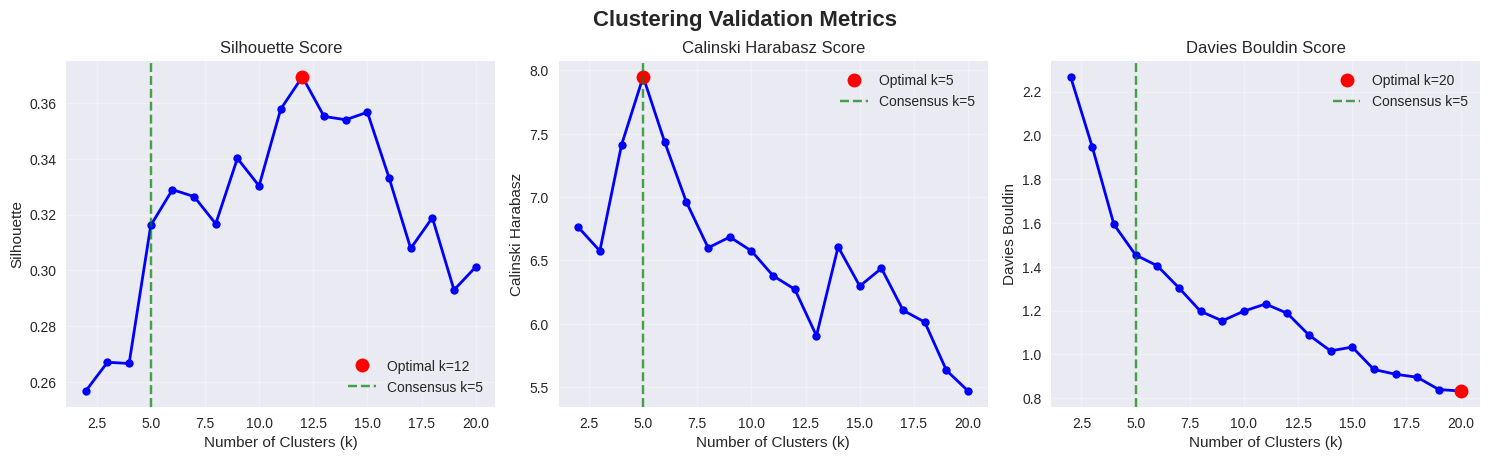

Optimal cluster selection results:
Consensus optimal k: 5
Method-specific optimal k values: {'silhouette': 12, 'calinski_harabasz': 5, 'davies_bouldin': 20, 'elbow': 5}
Consensus votes: {12: 1, 5: 2, 20: 1}


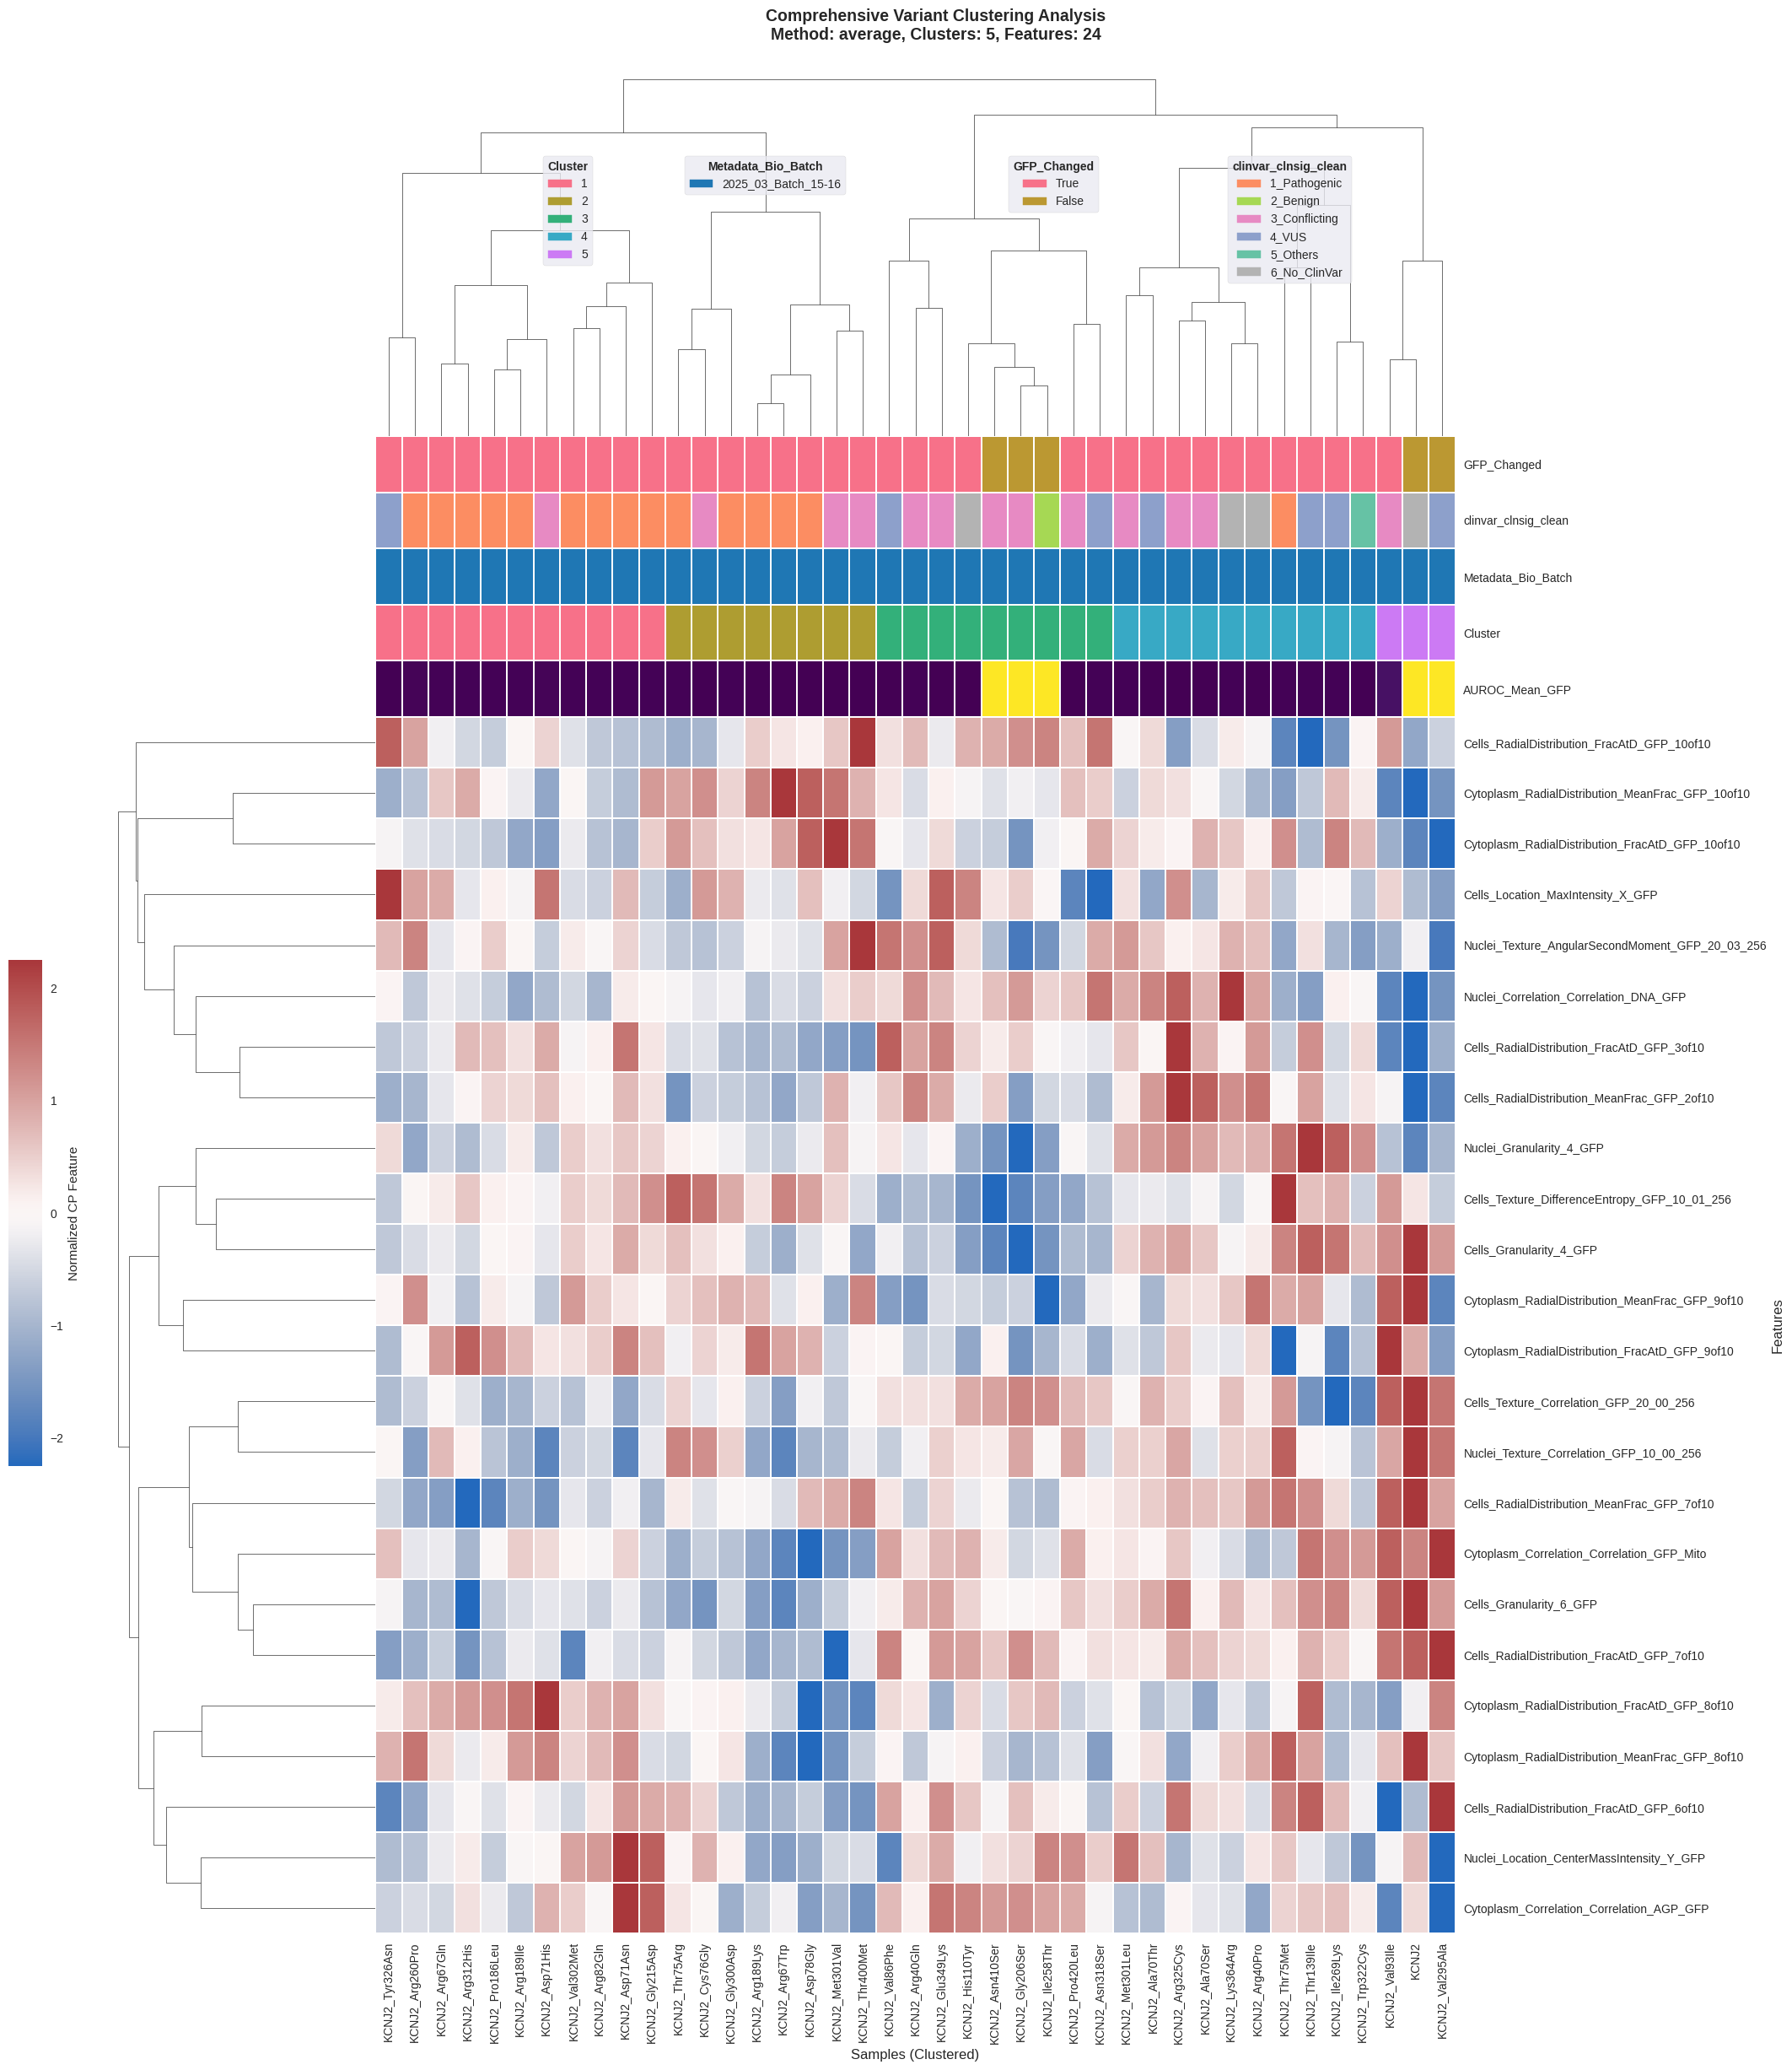

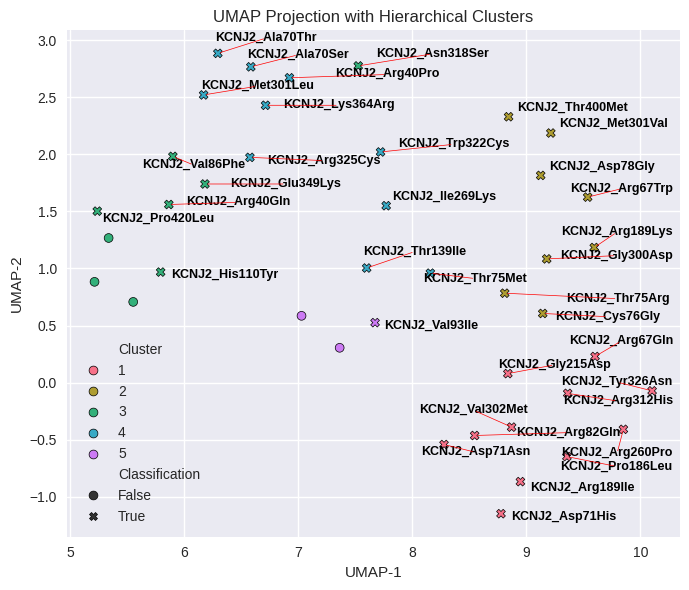

In [556]:
results_var_and_ref = robust_cosine_clustering_with_annotations(ref_var_allele_batch_proc_prof_df.to_pandas().set_index("Metadata_gene_allele"),
                                                    feature_cols=[col for col in non_null_cols_batch if col in ref_var_allele_batch_proc_prof_df.columns],
                                                    annotation_cols=[f"{feat}_Changed", "clinvar_clnsig_clean", "Metadata_Bio_Batch"],
                                                    continuous_annotations=[f"AUROC_Mean_{feat}"])
clustermap_var_and_ref = create_comprehensive_clustermap(ref_var_allele_batch_proc_prof_df.to_pandas().set_index("Metadata_gene_allele"), 
                                                         results_var_and_ref,
                                                         title_label=f"{gene}_{feat}_var_and_ref",
                                                         save_path="/home/shenrunx/igvf/varchamp/2021_09_01_VarChAMP_imgs")

### WRT to Ref

In [569]:
## Normalize var per batch
var_allele_prof_wrt_ref_df = pl.DataFrame()
for batch in ref_var_allele_batch_all_prof_df["Metadata_Bio_Batch"].unique():
    ref_var_allele_all_prof_batch = ref_var_allele_batch_all_prof_df.filter(
        pl.col("Metadata_Bio_Batch")==batch
    )
    batch_feat_cols = [col for col in ref_var_allele_all_prof_batch.columns if "Metadata" not in col]
    ## INT normalization per batch
    # ref_var_allele_all_prof_batch = inverse_normal_transform(ref_var_allele_all_prof_batch)
    batch_ref = ref_var_allele_all_prof_batch.filter(
        (~pl.col("Metadata_gene_allele").str.contains("_"))
    ).to_pandas().set_index("Metadata_gene_allele")[batch_feat_cols]
    # display(batch_ref)
    batch_var = ref_var_allele_all_prof_batch.filter(
        (pl.col("Metadata_gene_allele").str.contains("_"))
    ).to_pandas().set_index("Metadata_gene_allele")[batch_feat_cols]
    # display(batch_var)
    batch_var = batch_var - batch_ref.loc[gene]
    # display(batch_var)
    var_allele_prof_wrt_ref_df = pl.concat([
        var_allele_prof_wrt_ref_df, 
        pl.DataFrame(
            batch_var.reset_index()
        ).with_columns(
            pl.lit(batch).alias("Metadata_Bio_Batch")
        )
    ])

In [570]:
var_allele_prof_wrt_ref_df = inverse_normal_transform(var_allele_prof_wrt_ref_df)
var_allele_prof_wrt_ref_df = remove_corr_feats(var_allele_prof_wrt_ref_df)

non_null_cols_batch = [col for col in var_allele_prof_wrt_ref_df.columns if not var_allele_prof_wrt_ref_df[col].is_null().any() and "Metadata" not in col]
var_allele_meta_cols = [col for col in var_allele_prof_wrt_ref_df.columns if "Metadata" in col]
var_allele_prof_wrt_ref_df = var_allele_prof_wrt_ref_df.select(
    var_allele_meta_cols + [col for col in non_null_cols_batch if var_allele_prof_wrt_ref_df.select(pl.col(col).std()).item() != 0]
)

In [571]:
var_allele_prof_wrt_ref_df = var_allele_prof_wrt_ref_df.join(
    gene_variant_scores.select(
        [
            "gene_allele", "Metadata_Bio_Batch",
            f"Altered_95th_perc_{feat}", f"AUROC_Mean_{feat}",
            "clinvar_clnsig_clean",
        ]
    ), 
    left_on=["Metadata_gene_allele", "Metadata_Bio_Batch"],
    right_on=["gene_allele", "Metadata_Bio_Batch"],
    how="inner"
).with_columns(
    pl.col(f"Altered_95th_perc_{feat}").cast(pl.Boolean).alias(f"{feat}_Changed")
).with_columns(
    pl.col(f"{feat}_Changed").fill_null(False)
)

In [ ]:
results_var2wt = robust_cosine_clustering_with_annotations(var_allele_prof_wrt_ref_df.to_pandas().set_index("Metadata_gene_allele"),
                                                    feature_cols=[col for col in non_null_cols_batch if col in var_allele_prof_wrt_ref_df.columns],
                                                    annotation_cols=[f"{feat}_Changed", "clinvar_clnsig_clean"],
                                                    continuous_annotations=[f"AUROC_Mean_{feat}"])
clustermap_var2wt = create_comprehensive_clustermap(var_allele_prof_wrt_ref_df.to_pandas().set_index("Metadata_gene_allele"),
                                                    results_var2wt, 
                                                    title_label=f"{gene}_{feat}_norm_var_wrt_ref",
                                                    save_path="/home/shenrunx/igvf/varchamp/2021_09_01_VarChAMP_imgs")

In [501]:
## classification results in SM pipeline
def plot_top_n_important_feat(df, feat_cols, n=10, ax=None, title=""):
    # Calculate mean and standard deviation for each column
    column_stats = df[feat_cols].agg(['mean', 'std']).T

    # Sort columns by the sum of mean and std in descending order
    sorted_columns = column_stats.sort_values(by=["mean"], ascending=False)
    sorted_columns = sorted_columns.head(n)
    # display(sorted_columns)

    # Plot mean and std for each column
    if ax is None:
        fig, ax = plt.subplots(figsize=(5, 4))
    ax.barh(y=sorted_columns.index, width=sorted_columns["mean"], color='skyblue') ## yerr=sorted_columns["std"], capsize=5, edgecolor='black'
    ax.set_yticks(range(len(sorted_columns.index)))
    ax.set_yticklabels(sorted_columns.index, rotation=0, fontsize=10)
    # ax.set_xlabel("Mean")
    ax.set_title(f"Features Importance Mean {title}")
    ax.axvline(x=0.01, color='r', linestyle='--')
    # plt.tight_layout()
    # plt.show()
    return sorted_columns

feat_import_df_feat = pl.DataFrame()
for bio_rep in bio_reps:
    bio_rep_batches = BIO_REP_BATCHES_DICT[bio_rep]
    for batch_id in bio_rep_batches:
        # Read the data
        feat_df = pl.read_csv(f"{SM_CLASS_RES_DIR.format(batch_id=batch_id)}/feat_importance.csv")
        meta_cols = [c for c in feat_df.columns if c.startswith("Metadata_") or c.startswith("Group") or c == "Batch"]
        feat_cols = [c for c in feat_df.columns if c not in meta_cols]
        feat_df = feat_df.with_columns([
            pl.col(c).cast(pl.Float64) for c in feat_cols
        ])
        feat_df = feat_df.with_columns(
            pl.lit(batch_id).alias("Metadata_Batch"),
            pl.col("Group2").str.split('_').list.slice(-2).list.join("_").alias("Metadata_gene_allele")
        )
        if feat != "Morph":
            feat_cols = [
                i
                for i in feat_cols
                if (feat.lower() in i.lower())
                and ("Brightfield" not in i) ## excluding Brightfield features
            ]
        else:
            feat_cols = [
                i
                for i in feat_cols
                if ("GFP" not in i) and ("Brightfield" not in i)
            ]
        feat_df_batch = feat_df.filter(
            (pl.col("Metadata_Feature_Type")==feat)&(~pl.col("Metadata_Control"))&(pl.col("Group1").is_in(variant_list)|(pl.col("Metadata_gene_allele").is_in(variant_list)))
        ).select(meta_cols + feat_cols + ["Metadata_Batch", "Metadata_gene_allele"])
        feat_import_df_feat = pl.concat([feat_import_df_feat, feat_df_batch], how="diagonal")

In [502]:
# list(key_alleles_df["Metadata_gene_allele"])

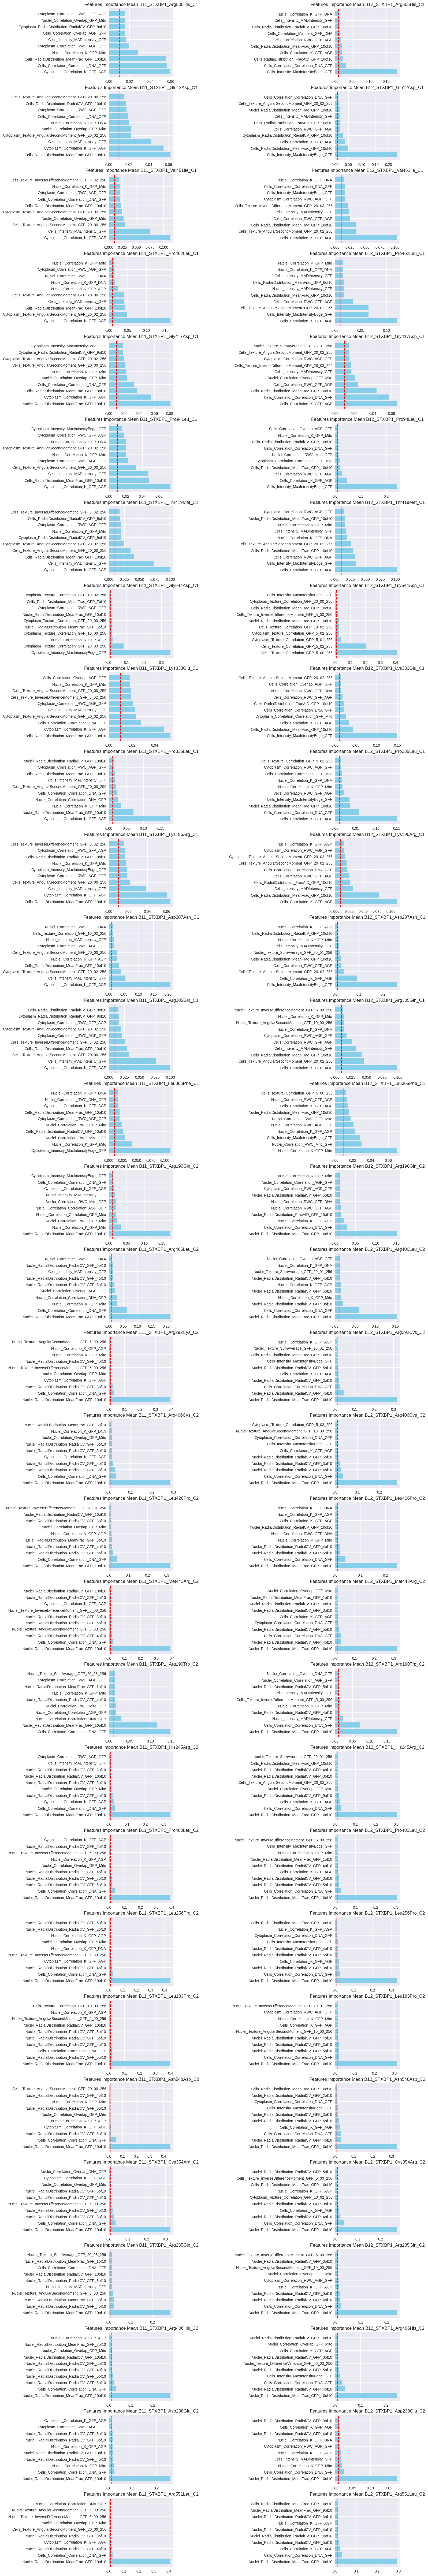

In [503]:
fig, axes = plt.subplots(clustermap_var2wt[clustermap_var2wt["Classification"]].shape[0], 2, figsize=(14, clustermap_var2wt[clustermap_var2wt["Classification"]].shape[0]*4))
key_alleles_df = clustermap_var2wt[clustermap_var2wt["Classification"]].sort_values("Cluster").reset_index()
for j, allele in key_alleles_df.iterrows():
    batch_list = list(feat_import_df_feat.filter(pl.col("Metadata_gene_allele")==allele["Metadata_gene_allele"]).unique("Metadata_Batch")["Metadata_Batch"])
    for i, batch in enumerate(batch_list):
        batch_df = feat_import_df_feat.filter((pl.col("Metadata_Batch")==batch)&(pl.col("Metadata_gene_allele")==allele["Metadata_gene_allele"]))
        non_null_gfp = [col for col in batch_df.columns if not batch_df[col].is_null().any() and "Metadata" not in col and "Group" not in col]
        batch_df_col = plot_top_n_important_feat(batch_df.to_pandas(), non_null_gfp, title="B"+batch.split("_")[-1]+"_"+allele["Metadata_gene_allele"]+f"_C{allele['Cluster']}", ax=axes[j,i])
plt.subplots_adjust(wspace=2.5)
plt.savefig(f"/home/shenrunx/igvf/varchamp/2021_09_01_VarChAMP_imgs/{gene}_{feat}_feat_importance.png", dpi=400)

## 3. Protein Structure

In [376]:
import requests
import glob
import gzip
import re
import os
import numpy as np
import py3Dmol
import polars as pl
from Bio.PDB import PDBParser
from Bio.SubsMat import MatrixInfo
from sklearn.cluster import AgglomerativeClustering

In [378]:
def get_uniprot_swissprot_id(protein_name: str) -> str:
    """
    Query UniProt’s REST search API to find the reviewed (Swiss‐Prot) accession
    for a given human gene/protein name. Returns None if not found.
    """
    url = "https://rest.uniprot.org/uniprotkb/search"
    # Build a query that:
    #  - matches the gene name exactly (using “gene:”)
    #  - restricts to human (organism_id:9606)
    #  - restricts to reviewed (Swiss‐Prot) entries
    query = f"gene:{protein_name} AND organism_id:9606 AND reviewed:true"
    params = {
        "query": query,
        "fields": "accession",
        "format": "json",
        "size": 1,      # only need the top hit
    }
    try:
        resp = requests.get(url, params=params, timeout=10)
        resp.raise_for_status()
        data = resp.json()
        results = data.get("results", [])
        if not results:
            return None
        return results[0]["primaryAccession"]
    except Exception:
        # If the request fails (e.g. no internet), return None
        return None

In [419]:
gene_uniprot_id = get_uniprot_swissprot_id(gene)
print(f"UniProt Swiss‐Prot ID for {gene}:", {gene_uniprot_id} or "Not found")

af2_struc_pdb_dir = "/data/shenrunx/igvf/varchamp/2025_laval_submitted/compare_ai_scores/1_inputs/new_raw_data/alphafold/UP000005640_9606_HUMAN_v4"

pdb_file = [pdb for pdb in glob.glob(f"{af2_struc_pdb_dir}/*.pdb.gz") if gene_uniprot_id in pdb][0]
pdb_file

UniProt Swiss‐Prot ID for MLH1: {'P40692'}


'/data/shenrunx/igvf/varchamp/2025_laval_submitted/compare_ai_scores/1_inputs/new_raw_data/alphafold/UP000005640_9606_HUMAN_v4/AF-P40692-F1-model_v4.pdb.gz'

In [420]:
import pandas as pd

# 3-letter to 1-letter AA conversion dictionary
three_to_one = {
    'ALA':'A', 'ARG':'R', 'ASN':'N', 'ASP':'D', 'CYS':'C',
    'GLN':'Q', 'GLU':'E', 'GLY':'G', 'HIS':'H', 'ILE':'I',
    'LEU':'L', 'LYS':'K', 'MET':'M', 'PHE':'F', 'PRO':'P',
    'SER':'S', 'THR':'T', 'TRP':'W', 'TYR':'Y', 'VAL':'V'
}

# Load BLOSUM62 matrix from Biopython
blosum62 = MatrixInfo.blosum62

def blosum62_score(wt, mut):
    key = (wt.upper(), mut.upper())
    if key not in blosum62:
        key = (mut.upper(), wt.upper())
    return blosum62.get(key)


miyata_dist = {
    'A':{'A':0.00,'R':0.91,'N':0.83,'D':0.88,'C':1.27,'Q':0.93,'E':0.94,'G':0.60,'H':1.00,'I':1.27,'L':1.23,'K':0.99,'M':1.05,'F':1.49,'P':0.74,'S':0.58,'T':0.64,'W':1.85,'Y':1.47,'V':1.14},
    'R':{'A':0.91,'R':0.00,'N':0.77,'D':1.04,'C':1.68,'Q':0.21,'E':0.44,'G':1.27,'H':0.39,'I':1.60,'L':1.54,'K':0.25,'M':1.39,'F':1.68,'P':0.95,'S':0.87,'T':1.12,'W':1.45,'Y':1.19,'V':1.54},
    'N':{'A':0.83,'R':0.77,'N':0.00,'D':0.24,'C':1.57,'Q':0.42,'E':0.54,'G':0.80,'H':0.56,'I':1.64,'L':1.65,'K':0.80,'M':1.59,'F':1.95,'P':1.13,'S':0.26,'T':0.37,'W':2.08,'Y':1.72,'V':1.49},
    'D':{'A':0.88,'R':1.04,'N':0.24,'D':0.00,'C':1.84,'Q':0.94,'E':0.22,'G':0.89,'H':0.89,'I':1.89,'L':1.83,'K':0.89,'M':1.76,'F':2.16,'P':1.38,'S':0.50,'T':0.82,'W':2.15,'Y':1.79,'V':1.66},
    'C':{'A':1.27,'R':1.68,'N':1.57,'D':1.84,'C':0.00,'Q':1.89,'E':1.90,'G':1.70,'H':1.42,'I':1.18,'L':1.08,'K':1.89,'M':1.04,'F':1.48,'P':1.94,'S':1.16,'T':1.30,'W':1.81,'Y':1.36,'V':1.07},
    'Q':{'A':0.93,'R':0.21,'N':0.42,'D':0.94,'C':1.89,'Q':0.00,'E':0.29,'G':1.31,'H':0.45,'I':1.55,'L':1.47,'K':0.28,'M':1.24,'F':1.59,'P':1.03,'S':0.74,'T':0.90,'W':1.57,'Y':1.20,'V':1.48},
    'E':{'A':0.94,'R':0.44,'N':0.54,'D':0.22,'C':1.90,'Q':0.29,'E':0.00,'G':1.09,'H':0.73,'I':1.66,'L':1.60,'K':0.42,'M':1.44,'F':1.85,'P':1.22,'S':0.60,'T':0.86,'W':1.77,'Y':1.40,'V':1.58},
    'G':{'A':0.60,'R':1.27,'N':0.80,'D':0.89,'C':1.70,'Q':1.31,'E':1.09,'G':0.00,'H':1.40,'I':1.59,'L':1.53,'K':1.28,'M':1.50,'F':1.92,'P':0.75,'S':0.47,'T':0.58,'W':2.08,'Y':1.70,'V':1.34},
    'H':{'A':1.00,'R':0.39,'N':0.56,'D':0.89,'C':1.42,'Q':0.45,'E':0.73,'G':1.40,'H':0.00,'I':1.71,'L':1.67,'K':0.56,'M':1.52,'F':1.69,'P':1.32,'S':0.90,'T':1.06,'W':1.25,'Y':0.96,'V':1.66},
    'I':{'A':1.27,'R':1.60,'N':1.64,'D':1.89,'C':1.18,'Q':1.55,'E':1.66,'G':1.59,'H':1.71,'I':0.00,'L':0.04,'K':1.62,'M':0.16,'F':0.39,'P':1.65,'S':1.21,'T':1.04,'W':1.84,'Y':1.46,'V':0.23},
    'L':{'A':1.23,'R':1.54,'N':1.65,'D':1.83,'C':1.08,'Q':1.47,'E':1.60,'G':1.53,'H':1.67,'I':0.04,'L':0.00,'K':1.57,'M':0.22,'F':0.61,'P':1.59,'S':1.14,'T':1.01,'W':1.77,'Y':1.39,'V':0.32},
    'K':{'A':0.99,'R':0.25,'N':0.80,'D':0.89,'C':1.89,'Q':0.28,'E':0.42,'G':1.28,'H':0.56,'I':1.62,'L':1.57,'K':0.00,'M':1.41,'F':1.73,'P':1.07,'S':0.63,'T':0.83,'W':1.55,'Y':1.18,'V':1.53},
    'M':{'A':1.05,'R':1.39,'N':1.59,'D':1.76,'C':1.04,'Q':1.24,'E':1.44,'G':1.50,'H':1.52,'I':0.16,'L':0.22,'K':1.41,'M':0.00,'F':0.60,'P':1.44,'S':1.10,'T':1.03,'W':1.84,'Y':1.43,'V':0.38},
    'F':{'A':1.49,'R':1.68,'N':1.95,'D':2.16,'C':1.48,'Q':1.59,'E':1.85,'G':1.92,'H':1.69,'I':0.39,'L':0.61,'K':1.73,'M':0.60,'F':0.00,'P':1.90,'S':1.56,'T':1.57,'W':1.28,'Y':0.38,'V':0.67},
    'P':{'A':0.74,'R':0.95,'N':1.13,'D':1.38,'C':1.94,'Q':1.03,'E':1.22,'G':0.75,'H':1.32,'I':1.65,'L':1.59,'K':1.07,'M':1.44,'F':1.90,'P':0.00,'S':0.75,'T':0.76,'W':2.19,'Y':1.76,'V':1.34},
    'S':{'A':0.58,'R':0.87,'N':0.26,'D':0.50,'C':1.16,'Q':0.74,'E':0.60,'G':0.47,'H':0.90,'I':1.21,'L':1.14,'K':0.63,'M':1.10,'F':1.56,'P':0.75,'S':0.00,'T':0.17,'W':1.88,'Y':1.53,'V':1.07},
    'T':{'A':0.64,'R':1.12,'N':0.37,'D':0.82,'C':1.30,'Q':0.90,'E':0.86,'G':0.58,'H':1.06,'I':1.04,'L':1.01,'K':0.83,'M':1.03,'F':1.57,'P':0.76,'S':0.17,'T':0.00,'W':1.92,'Y':1.56,'V':0.90},
    'W':{'A':1.85,'R':1.45,'N':2.08,'D':2.15,'C':1.81,'Q':1.57,'E':1.77,'G':2.08,'H':1.25,'I':1.84,'L':1.77,'K':1.55,'M':1.84,'F':1.28,'P':2.19,'S':1.88,'T':1.92,'W':0.00,'Y':0.58,'V':1.64},
    'Y':{'A':1.47,'R':1.19,'N':1.72,'D':1.79,'C':1.36,'Q':1.20,'E':1.40,'G':1.70,'H':0.96,'I':1.46,'L':1.39,'K':1.18,'M':1.43,'F':0.38,'P':1.76,'S':1.53,'T':1.56,'W':0.58,'Y':0.00,'V':1.26},
    'V':{'A':1.14,'R':1.54,'N':1.49,'D':1.66,'C':1.07,'Q':1.48,'E':1.58,'G':1.34,'H':1.66,'I':0.23,'L':0.32,'K':1.53,'M':0.38,'F':0.67,'P':1.34,'S':1.07,'T':0.90,'W':1.64,'Y':1.26,'V':0.00}
}

# max_dist = max(max(row.values()) for row in miyata_dist.values())
def miyata_score(wt, mut):
    wt = wt.upper()
    mut = mut.upper()
    if wt not in miyata_dist or mut not in miyata_dist[wt]:
        return None  # Unknown AA
    dist = miyata_dist[wt][mut]
    # Convert distance to similarity (higher score = more similar)
    return dist

In [421]:
# 1. Parse the structure
# 1) Open the .pdb.gz file with gzip.open in text/binary mode:
with gzip.open(pdb_file, "rt") as handle:
    parser = PDBParser(QUIET=True)
    structure = parser.get_structure("rho", handle)

    # 3. Rewind and read the entire PDB text
    handle.seek(0)
    pdb_text = handle.read()

# 2. Build a map: residue_number → (x, y, z) of its Cα atom
ca_coords = {}
for model in structure:
    for chain in model:
        if chain.get_id() == "A":
            for residue in chain:
                resnum = residue.get_id()[1]
                # Only consider standard amino acids with a CA atom
                if 'CA' in residue:
                    atom_ca = residue['CA']
                    ca_coords[resnum] = atom_ca.get_coord()

# 2) List of variants in “RHO_AminoAcidResidueNumberNewAminoAcid” format.
#    We assume that the PDB’s residue numbering matches exactly the numbers in these strings.
variants_raw_list = variant_list
# 3) The chain ID in the PDB that contains Rhodopsin.
#    If your PDB uses a different chain (e.g. “B”), adjust accordingly.
chain_id = "A"
# 4) If your PDB has insertion codes (e.g. 106A, 106B), you must handle that.
#    In this example, we assume no insertion codes (icode = " ").
default_icode = " "
# Confirm chain exists
model = structure[0]  # first (and usually only) model
if chain_id not in model:
    raise ValueError(f"Chain '{chain_id}' not found in {pdb_file}.")
# ---- STEP 2: Convert each raw‐string into (chain, resi, icode, label) ----
variant_list_pdb = []
pattern = re.compile(rf"{gene}_([A-Za-z]{{3}})(\d+)([A-Za-z]{{3}})")
for raw in variants_raw_list:
    m = pattern.match(raw)
    if not m:
        print(f"Warning: '{raw}' does not match expected pattern 'RHO_Aaa###Bbb'. Skipping.")
        continue
    wt_3letter, resi_str, mut_3letter = m.groups()
    resi = int(resi_str)
    
    # Residue-by-residue QC: check if residue exists and matches wild-type in PDB
    residue = None
    for model in structure:
        chain = model[chain_id]
        # Residue id: usually (' ', resi, ' ')
        res_id = (' ', resi, ' ')
        if res_id in chain:
            residue = chain[res_id]
            break

    if residue is None:
        print(f"Warning: residue number {resi} not found in chain {chain_id} in PDB. Skipping variant {raw}.")
        continue

    pdb_resname = residue.get_resname()  # 3-letter code from PDB
    if pdb_resname.upper() != wt_3letter.upper():
        print(f"Warning: residue mismatch at position {resi} for variant {raw}: "
              f"PDB has {pdb_resname}, variant expects {wt_3letter}. Skipping.")
        continue

    # Convert 3-letter to 1-letter
    wt_1letter = three_to_one.get(wt_3letter.upper(), "X")
    mut_1letter = three_to_one.get(mut_3letter.upper(), "X")

    # Calculate scores
    blosum_score = blosum62_score(wt_1letter, mut_1letter)
    miyata_sim = miyata_score(wt_1letter, mut_1letter)
    
    # Convert three‐letter codes to one‐letter for a concise label if you like.
    # Here, we'll keep the original string as the label.
    label = raw
    variant_list_pdb.append({
        "chain": chain_id,
        "resi": resi,
        "icode": default_icode,
        "label": label,
        "wt_aa": wt_1letter,
        "mut_aa": mut_1letter,
        "blosum62_score": blosum_score,
        "miyata_score": miyata_sim
    })

print(variant_list_pdb)
if not variant_list_pdb:
    raise RuntimeError("No valid variants found. Please check your variant strings.")

[{'chain': 'A', 'resi': 36, 'icode': ' ', 'label': 'MLH1_Ile36Met', 'wt_aa': 'I', 'mut_aa': 'M', 'blosum62_score': 1, 'miyata_score': 0.16}, {'chain': 'A', 'resi': 38, 'icode': ' ', 'label': 'MLH1_Asn38Lys', 'wt_aa': 'N', 'mut_aa': 'K', 'blosum62_score': 0, 'miyata_score': 0.8}, {'chain': 'A', 'resi': 681, 'icode': ' ', 'label': 'MLH1_Ala681Val', 'wt_aa': 'A', 'mut_aa': 'V', 'blosum62_score': 0, 'miyata_score': 1.14}, {'chain': 'A', 'resi': 147, 'icode': ' ', 'label': 'MLH1_Gly147Arg', 'wt_aa': 'G', 'mut_aa': 'R', 'blosum62_score': -2, 'miyata_score': 1.27}, {'chain': 'A', 'resi': 44, 'icode': ' ', 'label': 'MLH1_Ser44Phe', 'wt_aa': 'S', 'mut_aa': 'F', 'blosum62_score': -2, 'miyata_score': 1.56}, {'chain': 'A', 'resi': 160, 'icode': ' ', 'label': 'MLH1_Ala160Val', 'wt_aa': 'A', 'mut_aa': 'V', 'blosum62_score': 0, 'miyata_score': 1.14}, {'chain': 'A', 'resi': 653, 'icode': ' ', 'label': 'MLH1_Leu653Pro', 'wt_aa': 'L', 'mut_aa': 'P', 'blosum62_score': -3, 'miyata_score': 1.59}, {'chain':

In [422]:
misloc_alleles = imaging_summary.filter((pl.col("Altered_95th_perc_GFP")==1)&(pl.col("gene_allele").str.contains(gene)))["gene_allele"].unique()

In [423]:
# sns.displot(
#     data=imaging_summary_clinvar.filter((pl.col("gene_allele").str.contains(gene))).select([ ##(pl.col("Altered_95th_perc_GFP")==1)&
#         "gene_allele",
#         "AUROC_Mean_GFP",
#         'ESM1b_score',
#         'ESM1b_rankscore',
#         'ESM1b_pred',
#         'AlphaMissense_score',
#         'AlphaMissense_rankscore',
#         'AlphaMissense_pred']
#     ).to_pandas(),
#     x="AUROC_Mean_GFP",
#     hue="ESM1b_pred",
#     kind="hist",
#     common_norm=False
# )

In [424]:
pl.DataFrame(variant_list_pdb).filter(pl.col("label").is_in(misloc_alleles))

chain,resi,icode,label,wt_aa,mut_aa,blosum62_score,miyata_score
str,i64,str,str,str,str,i64,f64
"""A""",38,""" ""","""MLH1_Asn38Lys""","""N""","""K""",0,0.8
"""A""",681,""" ""","""MLH1_Ala681Val""","""A""","""V""",0,1.14
"""A""",147,""" ""","""MLH1_Gly147Arg""","""G""","""R""",-2,1.27
"""A""",44,""" ""","""MLH1_Ser44Phe""","""S""","""F""",-2,1.56
"""A""",160,""" ""","""MLH1_Ala160Val""","""A""","""V""",0,1.14
…,…,…,…,…,…,…,…
"""A""",244,""" ""","""MLH1_Gly244Asp""","""G""","""D""",-1,0.89
"""A""",318,""" ""","""MLH1_His318Gln""","""H""","""Q""",0,0.45
"""A""",582,""" ""","""MLH1_Leu582Val""","""L""","""V""",1,0.32


In [425]:
# Define 3D offsets for each residue
offsets_3d = {
    135: {'x': +1.0, 'y': +0.5, 'z': +0.5},
    110: {'x': -1.0, 'y': +0.5, 'z': +0.5},
    190: {'x':  0.0, 'y': -1.0, 'z': +0.5}
}

view = py3Dmol.view(width=800, height=600)
view.addModel(pdb_text, 'pdb')
view.setStyle({'cartoon': {'color': 'spectrum'}})

residues_to_label = [var['resi'] for var in variant_list_pdb]
# Get atom coordinates first to calculate proper offsets
for i, residue_info in enumerate(variant_list_pdb):
    resi = residue_info["resi"]
    color = 'red' if residue_info["label"] in misloc_alleles else 'blue'
    view.setStyle({'chain': 'A', 'resi': resi, 'atom': 'CA'}, {'sphere': {'color': color, 'radius': 0.9}})
    view.addResLabels({'chain': 'A', 'resi': resi}, 
                      {'fontColor': 'red' if color == 'red' else 'white', 'fontSize': 15, 'showBg': False})
    
view.zoomTo()
view.show()

# Save the interactive view as standalone HTML
html_content = view._make_html()
with open(f'protein_viewer_{gene}.html', 'w') as f:
    f.write(html_content)

3Dmol.js failed to load for some reason. Please check your browser console for error messages.